# Diabetic Retinopathy Grading from Retinal Fundus Photographs

**Body part / region:** Eye (retina)
**Imaging modality:** Color fundus photograph
**Problem type:** Classification, 5 classes (severity grading)
**Target classes:** No DR (0), Mild (1), Moderate (2), Severe (3), Proliferative DR (4),
following the International Clinical Diabetic Retinopathy (ICDR) severity scale
**Dataset source:** APTOS 2019 Blindness Detection, Aravind Eye Hospital / Asia
Pacific Tele-Ophthalmology Society, via Kaggle:
[https://www.kaggle.com/competitions/aptos2019-blindness-detection](https://www.kaggle.com/competitions/aptos2019-blindness-detection)
(dataset mirror without the competition join step:
[https://www.kaggle.com/datasets/mariaherrerot/aptos2019](https://www.kaggle.com/datasets/mariaherrerot/aptos2019)).
Accessed: *(fill in the date you download it)*.

Could a fundus photo be automatically graded for diabetic retinopathy severity, to
help prioritize which patients need urgent ophthalmologist review? This is aimed at
community vision-screening programs, exactly the situation this dataset was collected
for, where a technician can photograph a patient's retina faster than a specialist can
review every image on-site.

## Environment setup

Packages this notebook needs. `tensorflow`, `pandas`, `numpy`, `matplotlib`, and
`scikit-learn` usually come preinstalled in Google Colab, but they're listed
explicitly here so the notebook is reproducible on a fresh environment too.
`kagglehub` is very likely not preinstalled and is what downloads the dataset below.

In [1]:
!pip install -q kagglehub tensorflow pandas numpy matplotlib scikit-learn seaborn pillow


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python3.10 -m pip install --upgrade pip


### Downloading the dataset

`kagglehub` needs a Kaggle account. The first time you run this in Colab, it will
prompt you to either paste an API token or log in interactively, follow that prompt.
If you'd rather set it up yourself ahead of time: on kaggle.com go to
Settings -> API -> "Create New Token", which downloads a `kaggle.json` file, then
upload that file to Colab and run
`import os; os.environ['KAGGLE_CONFIG_DIR'] = '/content'` before the cell below (with
`kaggle.json` placed in `/content`).

Using the dataset mirror below to skip the "join competition" step the original
competition page requires. If it's unavailable for any reason, use
`kagglehub.competition_download('aptos2019-blindness-detection')` instead, after
joining the competition once on the Kaggle website.

In [2]:
import kagglehub

DATASET_PATH = kagglehub.dataset_download('mariaherrerot/aptos2019')
print(DATASET_PATH)

/home/student/.cache/kagglehub/datasets/mariaherrerot/aptos2019/versions/3


*Once downloaded: check the printed path's contents (e.g. with `!ls {DATASET_PATH}`)
and adjust `CSV_PATH` / `IMAGE_DIR` two cells below to match, dataset mirrors
occasionally nest files inside an extra subfolder.*

## A1. Problem Definition & Clinical Framing

This project grades a single retinal fundus photograph on a 5-point severity scale
for diabetic retinopathy (DR), a diabetes complication that damages blood vessels in
the retina and is a leading cause of preventable blindness. In plain terms: a
prediction of 0 (No DR) means the model sees no signs of the disease; 1-2 (Mild to
Moderate) means early changes are visible but urgency is lower; 3-4 (Severe to
Proliferative) means the model sees signs serious enough to warrant prompt
ophthalmologist review, since proliferative DR in particular can progress to
irreversible vision loss without timely treatment.

**This is a coursework prototype, not a diagnostic tool.** It has not been validated
on a clinical population, has not been reviewed by an ophthalmologist, and must not be
used to make, support, or delay any actual medical decision. It should only be used on
sample or test images for the purposes of this assignment.

Assumptions about the input image:
- A single, centered, in-focus color fundus photograph (the format the training
  images are in). A photo of anything other than a retina, or a very poor-quality or
  badly cropped fundus photo, is outside what this model has seen.
- Fundus photography specifically. Other retinal imaging modalities (OCT scans,
  fluorescein angiography) look nothing like this dataset's images and this model has
  no basis for interpreting them.

## A2. Dataset Documentation

**Source:** APTOS 2019 Blindness Detection, collected by Aravind Eye Hospital (India)
and hosted as a Kaggle competition by the Asia Pacific Tele-Ophthalmology Society.
Kaggle's terms permit this kind of coursework/research use of competition data.

**Size:** 3,662 labeled fundus images, each assigned a single severity grade by a
clinician. Images vary in resolution and aspect ratio, since they were captured with
different cameras across different clinic visits.

**Class distribution:** imbalanced, but less extremely than a typical skin-lesion
dataset. No DR makes up about half the data; Severe DR is the rarest class at around
5%. Still enough to distort a plain accuracy score, so per-class metrics matter here
too.

| Class | Meaning | Count |
|---|---|---|
| 0 | No DR | 1,805 |
| 1 | Mild | 370 |
| 2 | Moderate | 999 |
| 3 | Severe | 193 |
| 4 | Proliferative DR | 295 |

**Labelling:** each image was graded by a clinician on the ICDR 0-4 scale. As with any
single-rater grading scheme, there's some inherent subjectivity in distinguishing
adjacent grades (e.g. Moderate vs. Severe), which is worth keeping in mind when reading
the confusion matrix later, mistakes between neighboring grades are a different, more
forgivable kind of error than a mistake between "No DR" and "Proliferative DR".

**Known limitations:** images come from a single hospital system in India, so a model
trained on this data has no guarantee of generalizing to other populations, camera
equipment, or photography conditions. The class imbalance above also means the rarer
grades (particularly Severe) have comparatively little data for the model to learn
from.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CSV_PATH = f'{DATASET_PATH}/train_1.csv'     
IMAGE_DIR = f'{DATASET_PATH}/train_images/train_images'
metadata = pd.read_csv(CSV_PATH)
print(metadata.shape)
metadata.head()

(2930, 2)


,id_code,diagnosis
0,1ae8c165fd53,2
1,1b329a127307,1
2,1b32e1d775ea,4
3,1b3647865779,0
4,1b398c0494d1,0


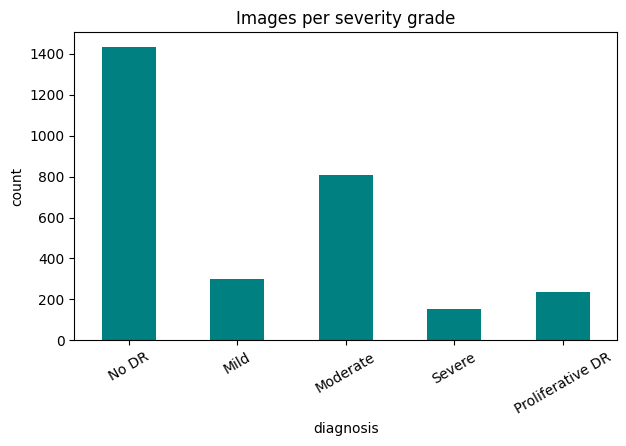

diagnosis
0    1434
1     300
2     808
3     154
4     234
Name: count, dtype: int64


In [4]:
CLASS_NAMES = {0: 'No DR', 1: 'Mild', 2: 'Moderate', 3: 'Severe', 4: 'Proliferative DR'}

counts = metadata['diagnosis'].value_counts().sort_index()

plt.figure(figsize=(7, 4))
counts.plot(kind='bar', color='teal')
plt.title('Images per severity grade')
plt.xticks(ticks=range(5), labels=[CLASS_NAMES[i] for i in range(5)], rotation=30)
plt.ylabel('count')
plt.show()

print(counts)

## A3. Data Preparation & Splitting

Each row in `train.csv` is one image from one patient visit, with no repeated or
linked images the way some other imaging datasets have, so a straightforward
stratified split by row is enough here, there's no shared-source grouping to account
for.

**Split proportions:** 70% train / 15% validation / 15% test, stratified by severity
grade so even the rarer classes (`Severe`, `Proliferative DR`) show up in all three
splits.

**Preprocessing applied to every image:**
- Resize to 224x224 (the input size MobileNetV2 expects).
- Scale pixel values to the [0, 1] range.
- On the training set only: random horizontal flip and small random rotation. Fundus
  photos don't have a single "correct" orientation the way, say, a chest X-ray does,
  so this is a safe way to get more effective variety out of a modest dataset. No
  augmentation is applied to validation or test images.

In [5]:
from sklearn.model_selection import train_test_split

IMG_SIZE = 224
CLASSES = [0, 1, 2, 3, 4]

train_df, temp_df = train_test_split(
    metadata, test_size=0.3, stratify=metadata['diagnosis'], random_state=7
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['diagnosis'], random_state=7
)

print('train:', len(train_df), ' val:', len(val_df), ' test:', len(test_df))

train: 2051  val: 439  test: 440


In [6]:
import tensorflow as tf
import numpy as np

def load_image(id_code, img_dir):
    path = tf.strings.join([img_dir, '/', id_code, '.png'])
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = img / 255.0
    return img

def augment(img):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], minval=0, maxval=4, dtype=tf.int32))
    return img

def make_dataset(df, img_dir, training=False, batch_size=32):
    ds = tf.data.Dataset.from_tensor_slices((df['id_code'].values, df['diagnosis'].values))

    if training:
        ds = ds.shuffle(1000)

    ds = ds.map(lambda code, label: (load_image(code, img_dir), label),
                num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.map(lambda img, label: (augment(img), label),
                    num_parallel_calls=tf.data.AUTOTUNE)

    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

# Explicitly mapping your actual split subfolders here
train_ds = make_dataset(train_df, IMAGE_DIR, training=True)
val_ds = make_dataset(val_df, IMAGE_DIR)
test_ds = make_dataset(test_df, IMAGE_DIR)

# Fixed the print lookups below by feeding it the train directory parameter
for images, labels in train_ds.take(1):
    print("Success! Batch shapes:")
    print("Images:", images.shape)
    print("Labels:", labels.shape)


I0000 00:00:1791963588.372909  604195 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791963588.805528  604195 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791963590.739472  604195 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1791963591.079732  604195 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Success! Batch shapes:
Images: (32, 224, 224, 3)
Labels: (32,)


## A4. Model Architecture & Justification

**Architecture:** MobileNetV2, pretrained on ImageNet, used as a frozen feature
extractor with a small classification head on top. With only 3,662 images total, and
under 200 in the rarest class, training a CNN from scratch would have far too little
data to learn reliable features. Transfer learning reuses the general-purpose visual
features MobileNetV2 already learned from ImageNet and only trains a small new head on
top. MobileNetV2 was chosen over a larger backbone (e.g. ResNet50) mainly for its
smaller saved model size, which matters once the model needs to load quickly inside
the Streamlit app.

**Input shape:** `(224, 224, 3)`, a resized RGB fundus image.
**Output shape:** `(5,)`, a softmax probability distribution over the 5 severity
grades. The predicted grade is the one with the highest probability, and that
probability is shown as the "confidence score" in the app.

**Alternatives considered:**
- Training from scratch was rejected for the data-size reason above.
- Treating this as an ordinal regression problem (since the grades have a real order,
  0 through 4) rather than plain classification would likely respect that ordering
  better, a mistake predicting grade 3 as grade 2 is a smaller error than predicting
  grade 3 as grade 0. Plain classification was kept here for simplicity, but this is a
  reasonable direction for a follow-up.

In [7]:
from tensorflow.keras import layers, models

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet'
)
base_model.trainable = False 

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(CLASSES), activation='softmax'),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## A5. Training Process

**Loss:** sparse categorical cross-entropy, the standard choice for multi-class
classification with integer labels.
**Optimizer:** Adam, learning rate 0.001.
**Batch size:** 32. **Epochs:** up to 15, with early stopping.

**Handling the class imbalance:** `class_weight`, computed as the inverse of each
class's frequency in the training set, is passed to `model.fit` so a mistake on the
rare `Severe` class counts for more during training than a mistake on the common
`No DR` class.

**Avoiding overfitting:** the base model stays frozen (see A4), which already limits
how much the model can overfit, since most of its parameters are never updated.
`EarlyStopping` monitors validation loss and stops training, restoring the
best-performing weights, if it hasn't improved for 3 epochs in a row.

In [8]:
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight('balanced', classes=np.array(CLASSES), y=train_df['diagnosis'].values)
class_weight = dict(zip(CLASSES, weights))
print(class_weight)

{0: np.float64(0.40856573705179283), 1: np.float64(1.9533333333333334), 2: np.float64(0.7260176991150442), 3: np.float64(3.7981481481481483), 4: np.float64(2.5012195121951217)}


In [9]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weight,
    callbacks=[early_stop],
)

Epoch 1/15


W0000 00:00:1791963595.306364  604277 cpu_allocator_impl.cc:82] Allocation of 51380224 exceeds 10% of free system memory.
W0000 00:00:1791963595.453852  604277 cpu_allocator_impl.cc:82] Allocation of 51380224 exceeds 10% of free system memory.
W0000 00:00:1791963595.544049  604277 cpu_allocator_impl.cc:82] Allocation of 154140672 exceeds 10% of free system memory.
W0000 00:00:1791963595.616845  604333 cpu_allocator_impl.cc:82] Allocation of 36636672 exceeds 10% of free system memory.
W0000 00:00:1791963595.668995  604277 cpu_allocator_impl.cc:82] Allocation of 156905472 exceeds 10% of free system memory.


65/65 ━━━━━━━━━━━━━━━━━━━━ 43s 617ms/step - accuracy: 0.4846 - loss: 1.5023 - val_accuracy: 0.6264 - val_loss: 0.8787
Epoch 2/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 39s 600ms/step - accuracy: 0.5846 - loss: 1.2134 - val_accuracy: 0.6378 - val_loss: 0.9110
Epoch 3/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 45s 690ms/step - accuracy: 0.6021 - loss: 1.1400 - val_accuracy: 0.6128 - val_loss: 0.8930
Epoch 4/15
65/65 ━━━━━━━━━━━━━━━━━━━━ 44s 671ms/step - accuracy: 0.6373 - loss: 1.0664 - val_accuracy: 0.5923 - val_loss: 0.9021


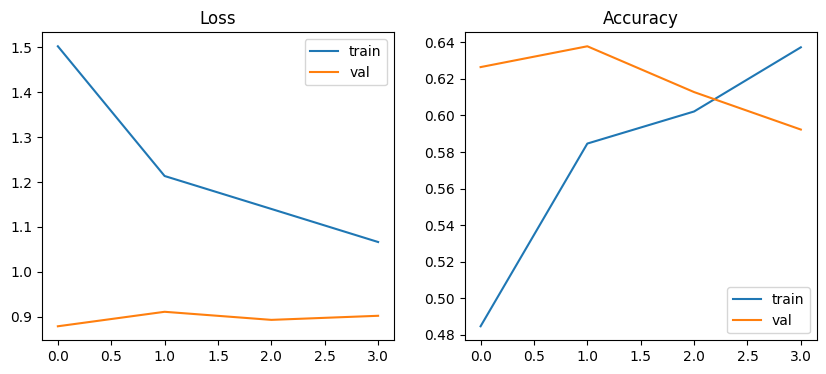

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(history.history['loss'], label='train')
ax[0].plot(history.history['val_loss'], label='val')
ax[0].set_title('Loss')
ax[0].legend()

ax[1].plot(history.history['accuracy'], label='train')
ax[1].plot(history.history['val_accuracy'], label='val')
ax[1].set_title('Accuracy')
ax[1].legend()
plt.show()

*Once this is run on the real dataset: comment here on what the curves actually show,
for example whether train and validation loss track closely (good sign) or whether
validation loss starts climbing while training loss keeps falling (overfitting, in
which case more dropout or stronger augmentation would be worth trying).*

## A6. Evaluation & Results

Accuracy alone would hide how the model does on the rarer, more clinically urgent
grades, so alongside it we look at a full classification report (precision, recall,
F1 per grade) and a confusion matrix, plus specific example predictions, including at
least one the model gets wrong.

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true, y_pred = [], []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

print(classification_report(y_true, y_pred, target_names=[CLASS_NAMES[c] for c in CLASSES], zero_division=0))

                  precision    recall  f1-score   support

           No DR       0.94      0.85      0.89       215
            Mild       0.27      0.67      0.39        45
        Moderate       0.63      0.18      0.28       122
          Severe       0.33      0.26      0.29        23
Proliferative DR       0.22      0.51      0.31        35

        accuracy                           0.59       440
       macro avg       0.48      0.49      0.43       440
    weighted avg       0.70      0.59      0.59       440



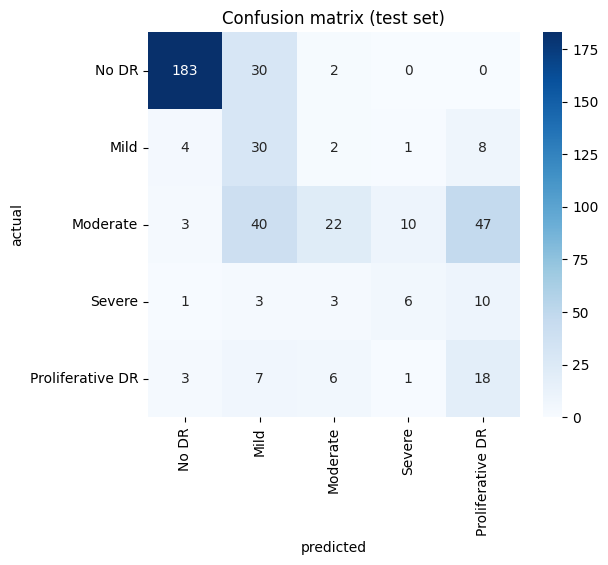

In [12]:
cm = confusion_matrix(y_true, y_pred, labels=CLASSES)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=[CLASS_NAMES[c] for c in CLASSES],
            yticklabels=[CLASS_NAMES[c] for c in CLASSES], cmap='Blues')
plt.xlabel('predicted')
plt.ylabel('actual')
plt.title('Confusion matrix (test set)')
plt.show()

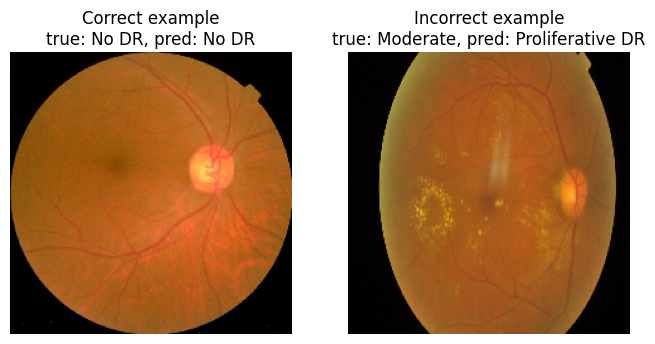

In [13]:
test_codes = test_df['id_code'].values
correct_idx = [i for i, (t, p) in enumerate(zip(y_true, y_pred)) if t == p]
wrong_idx = [i for i, (t, p) in enumerate(zip(y_true, y_pred)) if t != p]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, idx, title in zip(axes, [correct_idx[0], wrong_idx[0] if wrong_idx else correct_idx[1]],
                           ['Correct example', 'Incorrect example']):
    img = load_image(test_codes[idx], IMAGE_DIR).numpy()
    ax.imshow(img)
    ax.set_title(f'{title}\ntrue: {CLASS_NAMES[y_true[idx]]}, pred: {CLASS_NAMES[y_pred[idx]]}')
    ax.axis('off')
plt.show()

*Once this is run on the real dataset: write an honest paragraph here on where the
model struggles. Given the class imbalance and the subjectivity noted in A2, expect
confusion between adjacent grades (e.g. Moderate vs. Severe) to be more common than
confusion between distant grades, discuss whether that pattern shows up in the
confusion matrix above.*

## A7. Model Export

The trained model is saved in the native Keras format (`.keras`), using
TensorFlow/Keras 2.x. This bundles the architecture, weights, and optimizer state into
a single file that can be reloaded with `tf.keras.models.load_model` without needing
the original model-building code.

**Preprocessing that must be exactly reproduced at inference time (Part B):**
1. Decode the uploaded image as RGB (drop any alpha channel).
2. Resize to 224x224.
3. Scale pixel values to [0, 1] by dividing by 255.
4. No augmentation, that's a training-only step.

This is the same `load_image` logic used above, and the Streamlit app reuses it
directly rather than re-implementing it, so the two can't drift out of sync.

In [14]:
model.save('retinopathy_model.keras')
print('saved retinopathy_model.keras')

saved retinopathy_model.keras


## A8. Limitations, Ethics & Next Steps

**Generalisation limits.** The training data comes from a single hospital system in
India. There is no reason to assume this model performs equally well on other
populations, camera equipment, or photography conditions it hasn't seen. It has not
been tested on any population outside this dataset.

**False negatives vs. false positives.** In this context, a false negative (a case of
real Severe or Proliferative DR classified as No DR or Mild) is the more dangerous
error, since it could mean a patient who needs urgent treatment doesn't get referred
in time, and proliferative DR can progress to irreversible blindness. A false positive
(a mild or normal case flagged as more severe) causes an unnecessary referral, a real
cost, but a much smaller one than a missed diagnosis. This is exactly why a tool like
this needs clinical oversight: it's meant to help prioritize who gets seen sooner, not
to replace an ophthalmologist's actual grading.

**What would be needed before real-world use.** Validation on a separate,
independently collected dataset covering different populations and camera equipment;
a formal clinical evaluation comparing the model's grades against ophthalmologist
review, not just against this dataset's own single-rater labels; regulatory review
appropriate to a clinical decision-support tool; and a clear, tested workflow for what
happens when the model is unsure (see the Streamlit app's low-confidence handling in
Part B), rather than a plain prediction either way.